<a href="https://colab.research.google.com/github/sejal-oli7/Elevvo-Machine-Learning-Internship/blob/main/student_score_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

os.listdir("/content")

['.config',
 'student_score_model.pkl',
 'StudentPerformanceFactors.csv',
 'sample_data']

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_style("whitegrid")
print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
CSV_PATH  = "/content/StudentPerformanceFactors.csv"

df = pd.read_csv(CSV_PATH)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [ ]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [ ]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())



Missing values per column:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate rows: 0


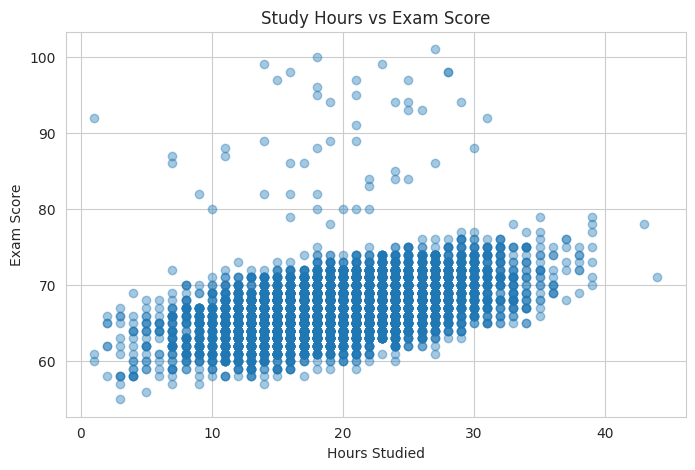

Correlation (Hours_Studied vs Exam_Score): 0.4455


In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Hours_Studied"], df["Exam_Score"], alpha=0.4)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")
plt.show()

print("Correlation (Hours_Studied vs Exam_Score):",
      round(df["Hours_Studied"].corr(df["Exam_Score"]), 4))

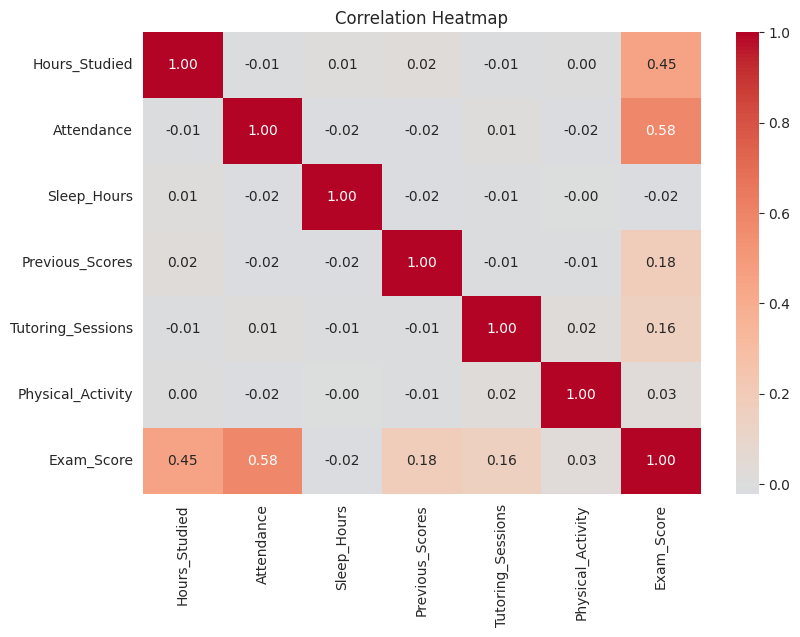

In [ ]:

# Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

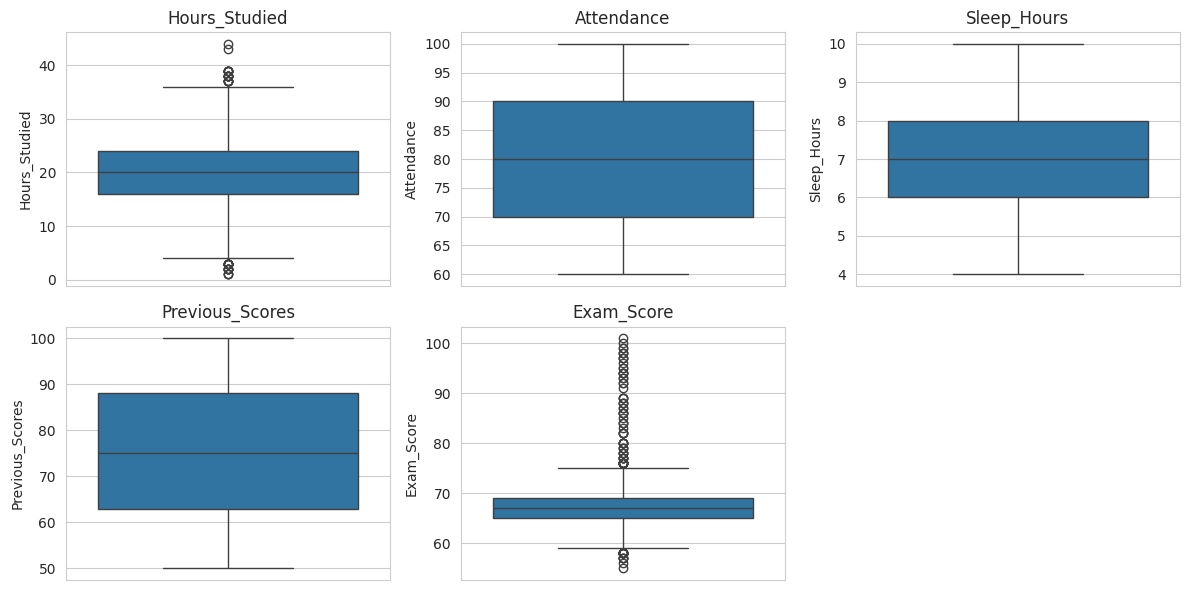

In [ ]:
#Boxplots
cols = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores", "Exam_Score"]
plt.figure(figsize=(12, 6))
for i, col in enumerate(cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
Q1, Q3 = df["Exam_Score"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
n_out = ((df["Exam_Score"] < lower) | (df["Exam_Score"] > upper)).sum()
print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}, bounds=({lower}, {upper})")
print("Rows outside bounds:", n_out, "(kept, real scores ho)")

Q1=65.0, Q3=69.0, IQR=4.0, bounds=(59.0, 75.0)
Rows outside bounds: 104 (kept, real scores ho)


In [ ]:
# Features, target, split
TARGET = "Exam_Score"
X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric features    :", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("\nTrain:", X_train.shape, " Test:", X_test.shape)


Numeric features    : ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Train: (5285, 19)  Test: (1322, 19)


In [ ]:
cols = ["Parental_Involvement", "Access_to_Resources", "Motivation_Level",
        "Family_Income", "Teacher_Quality", "Parental_Education_Level",
        "Distance_from_Home", "Peer_Influence"]
for c in cols:
    print(c, "->", df[c].dropna().unique().tolist())

Parental_Involvement -> ['Low', 'Medium', 'High']
Access_to_Resources -> ['High', 'Medium', 'Low']
Motivation_Level -> ['Low', 'Medium', 'High']
Family_Income -> ['Low', 'Medium', 'High']
Teacher_Quality -> ['Medium', 'High', 'Low']
Parental_Education_Level -> ['High School', 'College', 'Postgraduate']
Distance_from_Home -> ['Near', 'Moderate', 'Far']
Peer_Influence -> ['Positive', 'Negative', 'Neutral']


In [ ]:
# Preprocessing pipeline (ordinal + nominal + numeric)

# Order: sano -> thulo (Step 1 ko output sanga spelling milaunus)
ordinal_map = {
    "Parental_Involvement":     ["Low", "Medium", "High"],
    "Access_to_Resources":      ["Low", "Medium", "High"],
    "Motivation_Level":         ["Low", "Medium", "High"],
    "Family_Income":            ["Low", "Medium", "High"],
    "Teacher_Quality":          ["Low", "Medium", "High"],
    "Parental_Education_Level": ["High School", "College", "Postgraduate"],
    "Distance_from_Home":       ["Near", "Moderate", "Far"],
    "Peer_Influence":           ["Negative", "Neutral", "Positive"],
}
ordinal_features = list(ordinal_map)
nominal_features = [c for c in categorical_features if c not in ordinal_features]

print("Ordinal :", ordinal_features)
print("Nominal :", nominal_features)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ord", OrdinalEncoder(categories=list(ordinal_map.values()))),
    ("scaler", StandardScaler()),
])

nominal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("ord", ordinal_pipe, ordinal_features),
    ("cat", nominal_pipe, nominal_features),
])

Ordinal : ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income', 'Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home', 'Peer_Influence']
Nominal : ['Extracurricular_Activities', 'Internet_Access', 'School_Type', 'Learning_Disabilities', 'Gender']


In [ ]:
#Train Linear Regression
model = Pipeline([
    ("prep", preprocessor),
    ("reg", LinearRegression()),
])
model.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
# Evaluation (train vs test, 0-100 ma clip gareko)
def evaluate(model, X_, y_, name):
    pred = np.clip(model.predict(X_), 0, 100)
    mae = mean_absolute_error(y_, pred)
    rmse = np.sqrt(mean_squared_error(y_, pred))
    r2 = r2_score(y_, pred)
    print(f"{name:6s} -> MAE: {mae:.2f} | RMSE: {rmse:.2f} | R2: {r2:.4f}")
    return pred

_ = evaluate(model, X_train, y_train, "Train")
y_pred = evaluate(model, X_test, y_test, "Test")

Train  -> MAE: 0.49 | RMSE: 2.09 | R2: 0.7169
Test   -> MAE: 0.44 | RMSE: 1.80 | R2: 0.7709


In [ ]:
# Kun rows ma model dherai chukyo?
errors = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.round(2),
    "Error": (y_test.values - y_pred).round(2),
})
errors["AbsError"] = errors["Error"].abs()

print(errors.sort_values("AbsError", ascending=False).head(15))
print("\nRows with error > 3:", (errors["AbsError"] > 3).sum(), "of", len(errors))
print("Rows with Exam_Score > 100:", (df["Exam_Score"] > 100).sum())

      Actual  Predicted  Error  AbsError
28        89      61.15  27.85     27.85
704       98      71.02  26.98     26.98
1125      87      60.08  26.92     26.92
1144      93      67.58  25.42     25.42
721       97      72.96  24.04     24.04
480       88      67.93  20.07     20.07
945       80      65.08  14.92     14.92
448       65      66.51  -1.51      1.51
732       65      66.06  -1.06      1.06
522       66      67.03  -1.03      1.03
786       66      67.00  -1.00      1.00
676       64      63.00   1.00      1.00
974       67      68.00  -1.00      1.00
572       71      72.00  -1.00      1.00
718       68      68.98  -0.98      0.98

Rows with error > 3: 7 of 1322
Rows with Exam_Score > 100: 1


In [ ]:
high = errors[errors["Actual"] >= 80]
normal = errors[errors["Actual"] < 80]

print("High score rows (80+):", len(high))
print("R2 all rows      :", round(r2_score(errors["Actual"], errors["Predicted"]), 4))
print("R2 normal rows   :", round(r2_score(normal["Actual"], normal["Predicted"]), 4))

High score rows (80+): 7
R2 all rows      : 0.7709
R2 normal rows   : 0.9862


In [ ]:
bad_pos = errors.index[errors["AbsError"] > 3].to_numpy()
bad_rows = X_test.iloc[bad_pos][["Hours_Studied", "Attendance", "Previous_Scores", "Tutoring_Sessions"]].copy()
bad_rows["Actual"] = y_test.iloc[bad_pos].values
bad_rows["Predicted"] = y_pred[bad_pos].round(1)
bad_rows

,Hours_Studied,Attendance,Previous_Scores,Tutoring_Sessions,Actual,Predicted
217,19,70,54,0,89,61.1
2513,18,86,60,2,88,67.9
4192,28,90,91,0,98,71.0
5966,25,99,77,0,97,73.0
5989,18,61,91,3,80,65.1
2687,11,71,55,1,87,60.1
4531,26,69,95,0,93,67.6


In [ ]:
 # 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(model, X, y, cv=cv, scoring="r2")
print("CV R2 scores:", np.round(cv_r2, 4))
print(f"Mean CV R2: {cv_r2.mean():.4f} (+/- {cv_r2.std():.4f})")


CV R2 scores: [0.7709 0.7469 0.8972 0.6834 0.5893]
Mean CV R2: 0.7376 (+/- 0.1016)


num__Attendance                        2.291987
num__Hours_Studied                     1.755734
cat__Internet_Access_Yes               0.955759
cat__Learning_Disabilities_Yes        -0.853972
ord__Access_to_Resources               0.731229
num__Previous_Scores                   0.708058
ord__Parental_Involvement              0.699111
num__Tutoring_Sessions                 0.627107
cat__Extracurricular_Activities_Yes    0.577675
ord__Family_Income                     0.400371
ord__Peer_Influence                    0.396197
ord__Parental_Education_Level          0.375346
ord__Motivation_Level                  0.360600
ord__Teacher_Quality                   0.312597
ord__Distance_from_Home               -0.311641
dtype: float64


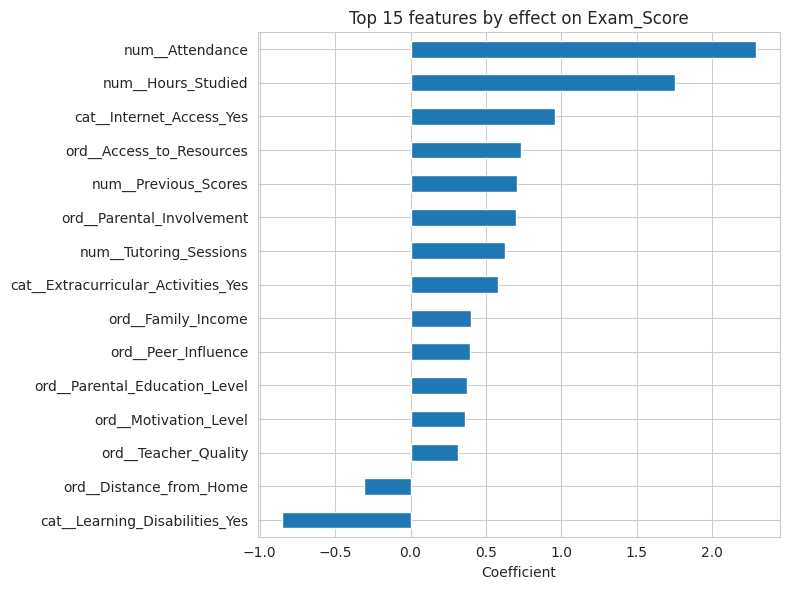

In [ ]:
#Coefficients (kun feature ko kati asar chha)
feature_names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model.named_steps["reg"].coef_, index=feature_names)
coefs = coefs.sort_values(key=abs, ascending=False)

print(coefs.head(15))

plt.figure(figsize=(8, 6))
coefs.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 features by effect on Exam_Score")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

,Actual Score,Predicted Score
0,65,64.62
1,65,65.29
2,71,71.51
3,64,64.30
4,66,66.42
5,66,66.57
6,72,72.51
7,66,66.37
8,70,70.00
9,70,70.04


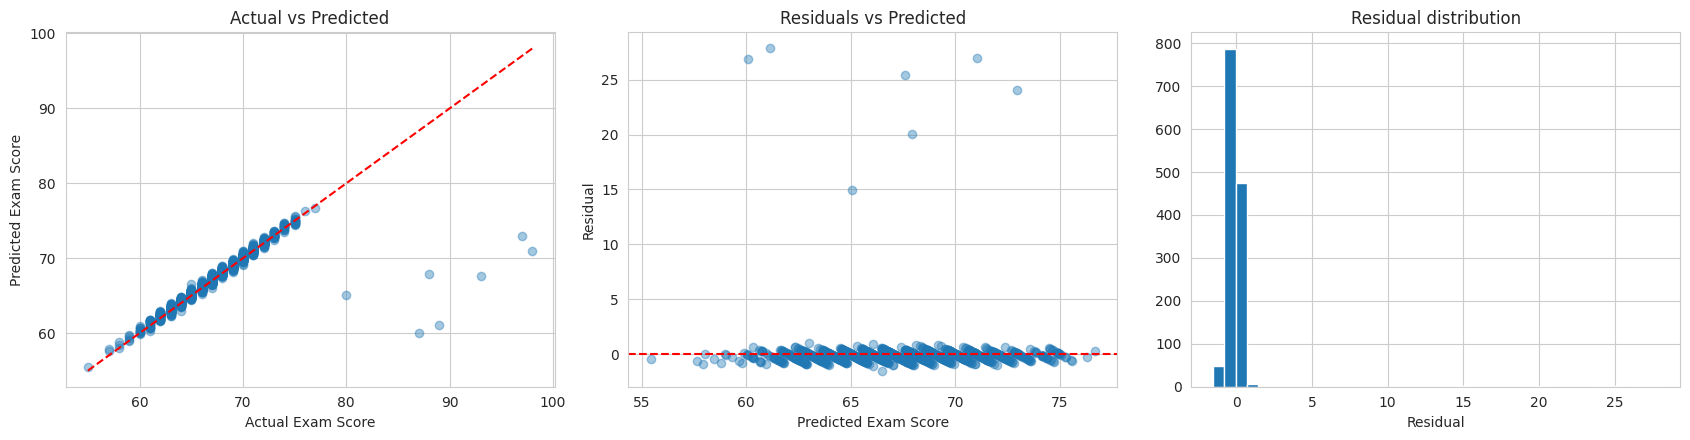

In [ ]:
#Actual vs predicted ra residual plots
results = pd.DataFrame({"Actual Score": y_test.values,
                        "Predicted Score": y_pred.round(2)})
display(results.head(10))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.4)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_xlabel("Actual Exam Score")
axes[0].set_ylabel("Predicted Exam Score")
axes[0].set_title("Actual vs Predicted")

# Residuals vs Predicted
residuals = y_test.values - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.4)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted Exam Score")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs Predicted")

# Residual distribution
axes[2].hist(residuals, bins=40)
axes[2].set_xlabel("Residual")
axes[2].set_title("Residual distribution")

plt.tight_layout()
plt.show()

In [ ]:
# Comparisons to others models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Huber": HuberRegressor(max_iter=1000),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

rows = []
for name, reg in models.items():
    pipe = Pipeline([("prep", preprocessor), ("reg", reg)])
    pipe.fit(X_train, y_train)
    pred = np.clip(pipe.predict(X_test), 0, 100)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

pd.DataFrame(rows).round(4).sort_values("R2", ascending=False)


,Model,MAE,RMSE,R2
0,Linear Regression,0.4443,1.7994,0.7709
1,Ridge,0.4443,1.7994,0.7709
2,Huber,0.4054,1.8003,0.7707
3,Random Forest,1.0712,2.1520,0.6724


In [ ]:
#New students score predictions
# Example: ek ota student ko data (columns dataset sanga match huna parcha)
new_student = X_test.iloc[[0]].copy()
new_student["Hours_Studied"] = 25
new_student["Attendance"] = 90

pred = np.clip(model.predict(new_student), 0, 100)[0]
print(f"Predicted Exam Score: {pred:.1f}")

Predicted Exam Score: 69.9


In [ ]:
df_clean = df[df["Exam_Score"] <= 100]
X_c = df_clean.drop(columns=[TARGET])
y_c = df_clean[TARGET]

cv_r2_c = cross_val_score(model, X_c, y_c, cv=cv, scoring="r2")
print("CV R2 (clean):", np.round(cv_r2_c, 4))
print(f"Mean CV R2: {cv_r2_c.mean():.4f} (+/- {cv_r2_c.std():.4f})")

CV R2 (clean): [0.8258 0.7665 0.7541 0.6261 0.7053]
Mean CV R2: 0.7355 (+/- 0.0669)


In [ ]:
r = permutation_importance(model, X_test, y_test, n_repeats=10,
                           random_state=42, scoring="r2")
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp)

Attendance                    0.745737
Hours_Studied                 0.452603
Access_to_Resources           0.067487
Previous_Scores               0.066575
Parental_Involvement          0.066378
Tutoring_Sessions             0.050171
Parental_Education_Level      0.022371
Family_Income                 0.021243
Motivation_Level              0.020680
Peer_Influence                0.019943
Teacher_Quality               0.015050
Distance_from_Home            0.014319
Extracurricular_Activities    0.008686
Learning_Disabilities         0.006992
Internet_Access               0.006788
Physical_Activity             0.004816
Gender                        0.000093
School_Type                   0.000039
Sleep_Hours                  -0.000123
dtype: float64


In [ ]:
import joblib
joblib.dump(model, "student_score_model.pkl")
print("Model saved!")

Model saved!


## Conclusion
- Final model: Linear Regression (ordinal + one-hot encoding)
- Test R2 (all rows): 0.7709 | Test MAE: 0.44 | Test RMSE: 1.80
- 5-fold CV R2: 0.7376 (+/- 0.10). The spread is large because a few extreme rows fall into different folds.
- Test R2 (rows with Actual < 80): 0.9862. This is a diagnostic only, because the rows are selected using the actual score.
- Most important features: Attendance, Hours_Studied
- Almost no effect: Sleep_Hours, Gender, School_Type
- Limitation: 7 test students with exam score 80-98 were predicted
  60-73 (errors of 15-28 marks). Their Hours_Studied, Attendance and
  Previous_Scores are in the normal range, so these high scores are not explained by
  the available features. They look like noise or unexplained cases, and they
  cause most of the error. Exam_Score also contains one impossible value (101).